In [1]:
# ============================================================
# SECTION 1: ENVIRONMENT SETUP
# ============================================================

!pip install scikit-learn scipy numpy pandas matplotlib seaborn joblib imbalanced-learn nptdms -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 171.8/171.8 kB 4.3 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
# ============================================================
# SECTION 2: IMPORTS
# ============================================================

import os
import re
import warnings
from dataclasses import dataclass, field
from typing import Callable, Optional

import numpy as np
import pandas as pd
import scipy.io as sio
from nptdms import TdmsFile
from scipy.stats import skew, kurtosis

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.decomposition import PCA
from imblearn.over_sampling import SMOTE

import matplotlib.pyplot as plt
import seaborn as sns
import joblib

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


In [4]:
# ============================================================
# SECTION 3: CONFIGURATION
# ============================================================

@dataclass
class Config:
    data_folder: str = '/content/drive/MyDrive/DATA/current_temp'   # UPDATE to this new dataset's folder
    output_folder: str = '/content/drive/MyDrive/DATA/Output'
    window_size: int = 1024
    test_size: float = 0.2
    random_state: int = RANDOM_STATE
    cv_folds: int = 5
    sampling_rate: float = 25600.0   # VERIFY against actual acquisition rate once known
    knn_param_grid: dict = field(default_factory=lambda: {
        'n_neighbors': [7, 9, 11, 15, 21, 25, 31],
        'weights': ['uniform', 'distance'],
        'metric': ['euclidean', 'manhattan', 'minkowski']
    })

CONFIG = Config()
os.makedirs(CONFIG.output_folder, exist_ok=True)
print("Configuration initialized.")
print(f"Data folder: {CONFIG.data_folder}")


Configuration initialized.
Data folder: /content/drive/MyDrive/DATA/current_temp


In [5]:
# ============================================================
# SECTION 4: DIAGNOSTIC — FILE FORMAT, COUNT, AND NAMING PATTERN
# ============================================================

all_files_in_folder = os.listdir(CONFIG.data_folder)
extensions = pd.Series([os.path.splitext(f)[1].lower() for f in all_files_in_folder]).value_counts()
print("File extensions found in folder:")
print(extensions)
print()

# Detect the dominant extension automatically
DETECTED_EXTENSION = extensions.index[0] if len(extensions) > 0 else None
print(f"Detected file extension: {DETECTED_EXTENSION}")

data_files = [f for f in all_files_in_folder if f.endswith(DETECTED_EXTENSION)]
print(f"\nTotal {DETECTED_EXTENSION} files: {len(data_files)}")
print(sorted(data_files)[:15], "..." if len(data_files) > 15 else "")

# Check for augmentation-style naming (as seen in the acoustic dataset)
augmented_pattern_count = sum(1 for f in data_files if re.search(r'_(orig|aug\d+)\.', f, re.IGNORECASE))
print(f"\nFiles matching '_orig' / '_augN' naming pattern: {augmented_pattern_count} / {len(data_files)}")
if augmented_pattern_count > 0:
    print("NOTE: This dataset appears to include augmented file variants, like the acoustic dataset did. "
          "Base-recording-level grouping (Section 7) will be used to prevent leakage between an original "
          "file and its own augmented copies.")


File extensions found in folder:
.tdms    45
Name: count, dtype: int64

Detected file extension: .tdms

Total .tdms files: 45
['0Nm_BPFI_03.tdms', '0Nm_BPFI_10.tdms', '0Nm_BPFI_30.tdms', '0Nm_BPFO_03.tdms', '0Nm_BPFO_10.tdms', '0Nm_BPFO_30.tdms', '0Nm_Misalign_01.tdms', '0Nm_Misalign_03.tdms', '0Nm_Misalign_05.tdms', '0Nm_Normal.tdms', '0Nm_Unbalance_0583mg.tdms', '0Nm_Unbalance_1169mg.tdms', '0Nm_Unbalance_1751mg.tdms', '0Nm_Unbalance_2239mg.tdms', '0Nm_Unbalance_3318mg.tdms'] ...

Files matching '_orig' / '_augN' naming pattern: 0 / 45


In [6]:
# ============================================================
# SECTION 5: DIAGNOSTIC — INSPECT ONE FILE'S INTERNAL STRUCTURE
# ============================================================

def inspect_tdms(filepath: str):
    tdms_file = TdmsFile.read(filepath)
    for group in tdms_file.groups():
        print(f"Group: {group.name}")
        for channel in group.channels():
            data = channel[:]
            print(f"  Channel: {channel.name} | length: {len(data)} | dtype: {data.dtype}")
            print(f"    First 5 values: {data[:5]}")


def inspect_mat(filepath: str):
    mat = sio.loadmat(filepath, squeeze_me=True, struct_as_record=False)
    for k, v in mat.items():
        if not k.startswith('__'):
            print(f"Key: {k}")
            print(f"  Type: {type(v)}")
            print(f"  Shape/attrs: {getattr(v, 'shape', getattr(v, '_fieldnames', 'N/A'))}")


sample_path = os.path.join(CONFIG.data_folder, data_files[0])
print(f"Inspecting: {data_files[0]}\n")

if DETECTED_EXTENSION == '.tdms':
    inspect_tdms(sample_path)
elif DETECTED_EXTENSION == '.mat':
    inspect_mat(sample_path)
else:
    print(f"Unrecognized extension '{DETECTED_EXTENSION}' — manual inspection needed.")


Inspecting: 0Nm_BPFI_30.tdms

Group: Test Information
Group: Log
  Channel: cDAQ9185-1F486B5Mod1/ai0 | length: 1536492 | dtype: float64
    First 5 values: [26.94708917 26.94708917 26.94708917 26.94708917 26.94708917]
  Channel: cDAQ9185-1F486B5Mod1/ai1 | length: 1536492 | dtype: float64
    First 5 values: [26.95840569 26.95840569 26.95840569 26.95840569 26.95840569]
  Channel: cDAQ9185-1F486B5Mod2/ai0 | length: 1536492 | dtype: float64
    First 5 values: [2.40317229 2.09186109 2.12751788 2.28660202 2.55128511]
  Channel: cDAQ9185-1F486B5Mod2/ai2 | length: 1536492 | dtype: float64
    First 5 values: [0.83957045 0.88627475 0.65137958 0.54423441 0.53873978]
  Channel: cDAQ9185-1F486B5Mod2/ai3 | length: 1536492 | dtype: float64
    First 5 values: [-2.33080293 -2.28489904 -2.1179758  -2.17222585 -2.37114271]


In [13]:
# ============================================================
# SECTION 6 (updated): LOADERS — handles unequal channel lengths
# ============================================================

DATA_GROUP_NAME = 'Log'
CURRENT_CHANNELS = ['cDAQ9185-1F486B5Mod2/ai0', 'cDAQ9185-1F486B5Mod2/ai2', 'cDAQ9185-1F486B5Mod2/ai3']
TEMPERATURE_CHANNELS = ['cDAQ9185-1F486B5Mod1/ai0', 'cDAQ9185-1F486B5Mod1/ai1']

def load_current_signal(filepath: str) -> np.ndarray:
    """
    Load current channel(s). Returns 1D (single channel) or 2D (multi-channel) array.
    Channels are truncated to their shortest common length before stacking,
    since some files in this dataset have a minor per-channel length
    mismatch (e.g. one channel logged a handful fewer samples than others).
    """
    tdms_file = TdmsFile.read(filepath)
    group = tdms_file[DATA_GROUP_NAME]
    if len(CURRENT_CHANNELS) == 1:
        return np.array(group[CURRENT_CHANNELS[0]][:]).flatten()

    channels = [np.array(group[ch][:]) for ch in CURRENT_CHANNELS]
    min_len = min(len(ch) for ch in channels)
    channels = [ch[:min_len] for ch in channels]
    return np.stack(channels, axis=1)


def load_temperature_signal(filepath: str) -> np.ndarray:
    """
    Load temperature channel(s). Returns 1D (single channel) or 2D (multi-channel) array.
    Same length-truncation safeguard as load_current_signal.
    """
    tdms_file = TdmsFile.read(filepath)
    group = tdms_file[DATA_GROUP_NAME]
    if len(TEMPERATURE_CHANNELS) == 1:
        return np.array(group[TEMPERATURE_CHANNELS[0]][:]).flatten()

    channels = [np.array(group[ch][:]) for ch in TEMPERATURE_CHANNELS]
    min_len = min(len(ch) for ch in channels)
    channels = [ch[:min_len] for ch in channels]
    return np.stack(channels, axis=1)

print(f"Loaders configured with length-mismatch handling: "
      f"{len(CURRENT_CHANNELS)} current channel(s), {len(TEMPERATURE_CHANNELS)} temperature channel(s).")

Loaders configured with length-mismatch handling: 3 current channel(s), 2 temperature channel(s).


In [14]:
# ============================================================
# SECTION 7: DATA ACQUISITION, SPLITTING, AND FEATURE MODULES
# ============================================================

def parse_label(filename: str) -> Optional[str]:
    """Extract the fault class label from a filename."""
    fname = filename.lower()
    if 'normal' in fname:
        return 'normal'
    elif 'bpfi' in fname:
        return 'inner_fault'
    elif 'bpfo' in fname:
        return 'outer_fault'
    elif 'misalign' in fname:
        return 'misalignment'
    elif 'unbalance' in fname or 'unbal' in fname:
        return 'unbalance'
    return None


def parse_load_condition(filename: str) -> str:
    """Extract the motor load condition (e.g. '0Nm') from a filename."""
    match = re.match(r'(\d+)Nm', filename)
    return f"{match.group(1)}Nm" if match else 'unknown'


def get_base_recording_id(filename: str) -> str:
    """
    Strip an '_orig'/'_augN' suffix (if present) to identify the base
    recording, so augmented copies of the same original stay together
    on one side of the train/test split. If no such suffix exists, the
    base recording is just the filename itself (no grouping needed beyond
    normal file-level splitting).
    """
    base = re.sub(r'_(orig|aug\d+)(\.\w+)$', r'\2', filename, flags=re.IGNORECASE)
    return base


def build_file_index(folder: str, extension: str) -> pd.DataFrame:
    """Construct an indexed DataFrame of labeled data files within a folder."""
    files = [f for f in os.listdir(folder) if f.endswith(extension)]
    records, unmatched = [], []
    for f in files:
        label = parse_label(f)
        if label is not None:
            records.append({
                'filename': f,
                'label': label,
                'load_condition': parse_load_condition(f),
                'base_recording': get_base_recording_id(f)
            })
        else:
            unmatched.append(f)
    if unmatched:
        print(f"Note: {len(unmatched)} file(s) excluded (no matching label keyword): "
              f"{unmatched[:10]}{' ...' if len(unmatched) > 10 else ''}")
    return pd.DataFrame(records).reset_index(drop=True)


def split_files_by_label(file_index: pd.DataFrame, test_size: float, random_state: int) -> tuple:
    """
    Split at the BASE RECORDING level (not individual filename), guaranteeing
    at least 1 base recording in test (and 1 remaining in train) for every
    class with 2+ base recordings. This ensures augmented variants of the
    same original recording never appear on both sides of the split.
    """
    # One row per unique (label, base_recording) combination
    base_df = file_index.drop_duplicates(subset=['base_recording'])[['base_recording', 'label']]

    train_bases, test_bases = [], []
    for label, group in base_df.groupby('label'):
        n = len(group)
        if n < 2:
            print(f"WARNING: class '{label}' has only {n} base recording(s) — cannot be split. "
                  f"All variants placed in TRAINING; no test representation for this class.")
            train_bases.append(group['base_recording'])
            continue
        n_test = max(1, round(n * test_size))
        n_test = min(n_test, n - 1)
        g_train, g_test = train_test_split(group['base_recording'], test_size=n_test, random_state=random_state)
        train_bases.append(g_train)
        test_bases.append(g_test)

    train_base_set = set(pd.concat(train_bases)) if train_bases else set()
    test_base_set = set(pd.concat(test_bases)) if test_bases else set()

    train_files = file_index[file_index['base_recording'].isin(train_base_set)].reset_index(drop=True)
    test_files = file_index[file_index['base_recording'].isin(test_base_set)].reset_index(drop=True)
    return train_files, test_files


def segment_signal(signal: np.ndarray, window_size: int, overlap: float = 0.0) -> np.ndarray:
    """Segment a signal (1D or 2D multi-channel) into fixed-length windows."""
    is_1d = (signal.ndim == 1)
    signal_2d = signal.reshape(-1, 1) if is_1d else signal
    step = max(1, int(window_size * (1 - overlap)))
    n_windows = max(0, (signal_2d.shape[0] - window_size) // step + 1)
    windows = np.array([signal_2d[i * step: i * step + window_size, :] for i in range(n_windows)])
    return windows[:, :, 0] if is_1d else windows


def extract_time_domain_features(window: np.ndarray) -> list:
    """8 time-domain features, NaN-safe for zero-variance (flat) windows."""
    std_dev = np.std(window)
    rms = np.sqrt(np.mean(window ** 2))
    peak = np.max(np.abs(window))
    if std_dev < 1e-10:
        skewness_val, kurtosis_val = 0.0, 0.0
    else:
        skewness_val = skew(window)
        kurtosis_val = kurtosis(window)
        skewness_val = 0.0 if not np.isfinite(skewness_val) else skewness_val
        kurtosis_val = 0.0 if not np.isfinite(kurtosis_val) else kurtosis_val
    return [
        np.mean(window), std_dev, rms, peak,
        np.max(window) - np.min(window),
        skewness_val, kurtosis_val,
        peak / (rms + 1e-8)
    ]


def extract_features_any_channels(window: np.ndarray) -> list:
    """Handles both single-channel (1D window) and multi-channel (2D window) input."""
    if window.ndim == 1:
        return extract_time_domain_features(window)
    all_features = []
    for ch in range(window.shape[1]):
        all_features.extend(extract_time_domain_features(window[:, ch]))
    return all_features


def build_feature_matrix(file_index: pd.DataFrame, folder: str, loader_fn: Callable,
                          window_size: int) -> tuple:
    """Build feature matrix, label vector, and group vector (base_recording per window)."""
    features, labels, groups = [], [], []
    failed_files = []
    for _, row in file_index.iterrows():
        filepath = os.path.join(folder, row['filename'])
        try:
            signal = loader_fn(filepath)
        except Exception as exc:
            failed_files.append((row['filename'], str(exc)))
            continue
        windows = segment_signal(signal, window_size, overlap=0.0)
        for window in windows:
            features.append(extract_features_any_channels(window))
            labels.append(row['label'])
            groups.append(row['base_recording'])
    if failed_files:
        print(f"Warning: {len(failed_files)} file(s) failed to load:")
        for fname, err in failed_files:
            print(f"  - {fname}: {err}")
    return np.array(features), np.array(labels), np.array(groups)

print("Data acquisition, splitting, and feature modules loaded (base-recording-aware).")


Data acquisition, splitting, and feature modules loaded (base-recording-aware).


In [15]:
# ============================================================
# SECTION 8: MODEL TRAINING AND EVALUATION MODULE
# ============================================================

class KNNFaultClassifier:
    """KNN training/evaluation for one sensor, given pre-split, pre-featurized data."""

    def __init__(self, sensor_name: str, config: Config):
        self.sensor_name = sensor_name
        self.config = config
        self.scaler = StandardScaler()

    def fit(self, X_train, y_train, groups_train, X_test, y_test, use_smote: bool = True):
        self.X_train, self.y_train, self.groups_train = X_train, y_train, groups_train
        self.X_test, self.y_test = X_test, y_test

        self.X_train_scaled = self.scaler.fit_transform(self.X_train)
        self.X_test_scaled = self.scaler.transform(self.X_test)

        if use_smote:
            min_class_size = pd.Series(self.y_train).value_counts().min()
            k_neighbors = max(1, min(5, min_class_size - 1))
            try:
                smote = SMOTE(random_state=self.config.random_state, k_neighbors=k_neighbors)
                X_train_final, y_train_final = smote.fit_resample(self.X_train_scaled, self.y_train)
                print(f"[{self.sensor_name}] SMOTE applied: {len(self.y_train)} -> {len(y_train_final)} samples")
            except Exception as exc:
                print(f"[{self.sensor_name}] SMOTE skipped ({exc})")
                X_train_final, y_train_final = self.X_train_scaled, self.y_train
        else:
            X_train_final, y_train_final = self.X_train_scaled, self.y_train

        n_groups = len(set(self.groups_train))
        n_splits = min(self.config.cv_folds, n_groups) if n_groups >= 2 else 2
        cv_strategy = StratifiedGroupKFold(n_splits=max(2, n_splits), shuffle=True,
                                             random_state=self.config.random_state)
        grid_search = GridSearchCV(
            estimator=KNeighborsClassifier(),
            param_grid=self.config.knn_param_grid,
            cv=cv_strategy,
            scoring='f1_weighted',
            n_jobs=-1
        )
        grid_search.fit(self.X_train_scaled, self.y_train, groups=self.groups_train)

        self.grid_search_results = grid_search
        self.best_model = KNeighborsClassifier(**grid_search.best_params_)
        self.best_model.fit(X_train_final, y_train_final)

        self._evaluate()
        return self

    def _evaluate(self):
        y_pred = self.best_model.predict(self.X_test_scaled)
        accuracy = accuracy_score(self.y_test, y_pred)
        precision, recall, f1, _ = precision_recall_fscore_support(
            self.y_test, y_pred, average='weighted', zero_division=0
        )
        self.metrics = {
            'accuracy': accuracy, 'precision': precision, 'recall': recall, 'f1_score': f1,
            'best_params': self.grid_search_results.best_params_,
            'cv_best_score': self.grid_search_results.best_score_
        }
        self.y_pred = y_pred

    def summary(self) -> pd.DataFrame:
        return pd.DataFrame([{
            'Sensor': self.sensor_name,
            'Best K': self.metrics['best_params']['n_neighbors'],
            'Weights': self.metrics['best_params']['weights'],
            'Metric': self.metrics['best_params']['metric'],
            'CV F1 (grouped)': round(self.metrics['cv_best_score'], 4),
            'Test Accuracy': round(self.metrics['accuracy'], 4),
            'Precision': round(self.metrics['precision'], 4),
            'Recall': round(self.metrics['recall'], 4),
            'F1-Score': round(self.metrics['f1_score'], 4)
        }])

    def print_report(self):
        print(f"{'=' * 60}")
        print(f"KNN Classification Report — {self.sensor_name}")
        print(f"{'=' * 60}")
        print(f"Best hyperparameters: {self.metrics['best_params']}")
        print(f"Grouped CV weighted-F1: {self.metrics['cv_best_score']:.4f}")
        print(f"Held-out test accuracy: {self.metrics['accuracy']:.4f}\n")
        print(classification_report(self.y_test, self.y_pred, zero_division=0))

print("Model training module loaded.")


Model training module loaded.


In [16]:
# ============================================================
# SECTION 9: VISUALIZATION MODULE
# ============================================================

def plot_confusion_matrix(clf, save_path: str = None):
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(clf.y_test, clf.y_pred, cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(f'Confusion Matrix — KNN ({clf.sensor_name})')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


def plot_pca_projection(X, y, sensor_name, save_path=None):
    X_scaled = StandardScaler().fit_transform(X)
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    X_pca = pca.fit_transform(X_scaled)
    plt.figure(figsize=(7, 6))
    for label in np.unique(y):
        mask = y == label
        plt.scatter(X_pca[mask, 0], X_pca[mask, 1], label=label, alpha=0.6, s=15)
    plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}% variance)')
    plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}% variance)')
    plt.title(f'PCA Projection — {sensor_name} (Training Set)')
    plt.legend(title='Class')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

print("Visualization module loaded.")


Visualization module loaded.


In [17]:
# ============================================================
# SECTION 10: SHARED FILE INDEX AND BASE-RECORDING-LEVEL SPLIT
# ============================================================

file_index = build_file_index(CONFIG.data_folder, DETECTED_EXTENSION)
print("File distribution (all files):")
print(file_index['label'].value_counts())
print(f"\nUnique base recordings: {file_index['base_recording'].nunique()} "
      f"(vs {len(file_index)} total files — a big gap confirms heavy augmentation)")

train_files, test_files = split_files_by_label(file_index, CONFIG.test_size, CONFIG.random_state)
print(f"\nTraining files: {len(train_files)}  |  Test files: {len(test_files)}")
print("\nTraining label distribution:")
print(train_files['label'].value_counts())
print("\nTest label distribution:")
print(test_files['label'].value_counts())


File distribution (all files):
label
unbalance       15
inner_fault      9
outer_fault      9
misalignment     9
normal           3
Name: count, dtype: int64

Unique base recordings: 45 (vs 45 total files — a big gap confirms heavy augmentation)

Training files: 35  |  Test files: 10

Training label distribution:
label
unbalance       12
inner_fault      7
outer_fault      7
misalignment     7
normal           2
Name: count, dtype: int64

Test label distribution:
label
unbalance       3
inner_fault     2
outer_fault     2
misalignment    2
normal          1
Name: count, dtype: int64


In [18]:
# ============================================================
# SECTION 11a: CURRENT — FEATURE EXTRACTION
# ============================================================

X_current_train, y_current_train, groups_current_train = build_feature_matrix(
    train_files, CONFIG.data_folder, load_current_signal, CONFIG.window_size
)
X_current_test, y_current_test, _ = build_feature_matrix(
    test_files, CONFIG.data_folder, load_current_signal, CONFIG.window_size
)
print(f"Current training feature matrix: {X_current_train.shape}")
print(f"Current test feature matrix: {X_current_test.shape}")
print("NaN check — train:", np.isnan(X_current_train).sum(), " test:", np.isnan(X_current_test).sum())


  - 0Nm_BPFO_03.tdms: The DType <class 'numpy.dtypes.Float64DType'> could not be promoted by <class 'numpy.dtypes.VoidDType'>. This means that no common DType exists for the given inputs. For example they cannot be stored in a single array unless the dtype is `object`. The full list of DTypes is: (<class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.VoidDType'>, <class 'numpy.dtypes.VoidDType'>)
  - 0Nm_BPFO_30.tdms: The DType <class 'numpy.dtypes.Float64DType'> could not be promoted by <class 'numpy.dtypes.VoidDType'>. This means that no common DType exists for the given inputs. For example they cannot be stored in a single array unless the dtype is `object`. The full list of DTypes is: (<class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.VoidDType'>, <class 'numpy.dtypes.VoidDType'>)
  - 2Nm_BPFO_10.tdms: The DType <class 'numpy.dtypes.Float64DType'> could not be promoted by <class 'numpy.dtypes.VoidDType'>. This means that no common DType exists for the given inputs. For 

In [19]:
# ============================================================
# SECTION 11b: CURRENT — MODEL TRAINING
# ============================================================

current_classifier = KNNFaultClassifier(sensor_name='Current', config=CONFIG)
current_classifier.fit(X_current_train, y_current_train, groups_current_train,
                        X_current_test, y_current_test, use_smote=True)
current_classifier.print_report()


[Current] SMOTE applied: 73500 -> 144000 samples
KNN Classification Report — Current
Best hyperparameters: {'metric': 'manhattan', 'n_neighbors': 7, 'weights': 'distance'}
Grouped CV weighted-F1: 0.6759
Held-out test accuracy: 0.5247

              precision    recall  f1-score   support

 inner_fault       0.80      0.84      0.82      3000
misalignment       0.88      0.80      0.84      6000
      normal       0.00      0.00      0.00      7502
   unbalance       0.43      0.67      0.53      9000

    accuracy                           0.52     25502
   macro avg       0.53      0.58      0.55     25502
weighted avg       0.45      0.52      0.48     25502



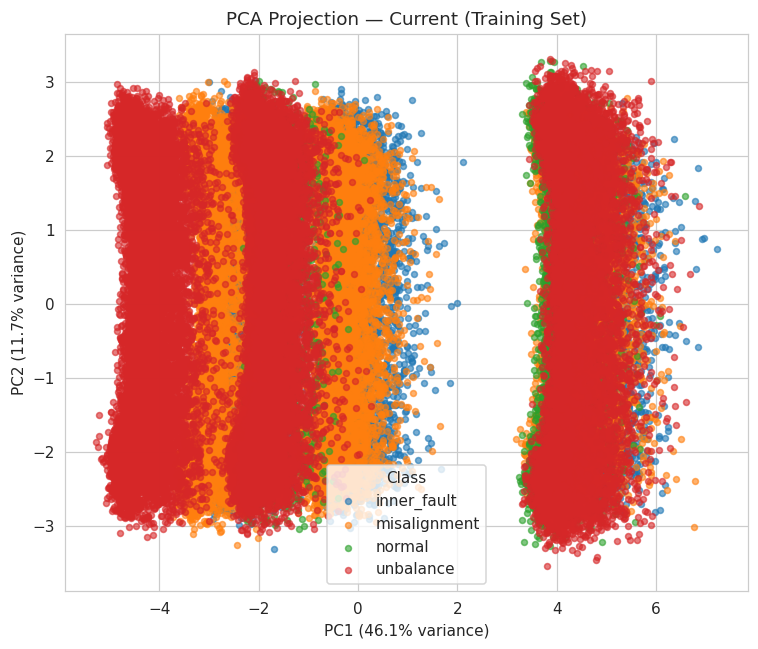

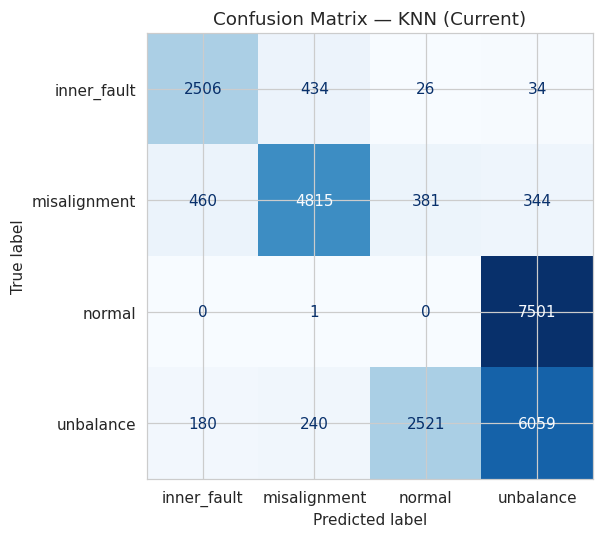

In [20]:
# ============================================================
# SECTION 11c: CURRENT — VISUALIZATION
# ============================================================

out = CONFIG.output_folder
plot_pca_projection(X_current_train, y_current_train, 'Current', save_path=f'{out}/current_pca_new.png')
plot_confusion_matrix(current_classifier, save_path=f'{out}/current_confusion_matrix_new.png')


In [21]:
# ============================================================
# SECTION 12a: TEMPERATURE — FEATURE EXTRACTION
# ============================================================

X_temp_train, y_temp_train, groups_temp_train = build_feature_matrix(
    train_files, CONFIG.data_folder, load_temperature_signal, CONFIG.window_size
)
X_temp_test, y_temp_test, _ = build_feature_matrix(
    test_files, CONFIG.data_folder, load_temperature_signal, CONFIG.window_size
)
print(f"Temperature training feature matrix: {X_temp_train.shape}")
print(f"Temperature test feature matrix: {X_temp_test.shape}")
print("NaN check — train:", np.isnan(X_temp_train).sum(), " test:", np.isnan(X_temp_test).sum())


Temperature training feature matrix: (84000, 16)
Temperature test feature matrix: (28502, 16)
NaN check — train: 0  test: 0


In [22]:
# ============================================================
# SECTION 12b: TEMPERATURE — MODEL TRAINING
# ============================================================

temperature_classifier = KNNFaultClassifier(sensor_name='Temperature', config=CONFIG)
temperature_classifier.fit(X_temp_train, y_temp_train, groups_temp_train,
                            X_temp_test, y_temp_test, use_smote=True)
temperature_classifier.print_report()


[Temperature] SMOTE applied: 84000 -> 180000 samples
KNN Classification Report — Temperature
Best hyperparameters: {'metric': 'euclidean', 'n_neighbors': 25, 'weights': 'uniform'}
Grouped CV weighted-F1: 0.5379
Held-out test accuracy: 0.5281

              precision    recall  f1-score   support

 inner_fault       0.09      0.05      0.07      3000
misalignment       0.96      0.95      0.95      6000
      normal       0.20      0.05      0.08      7502
 outer_fault       0.59      0.73      0.65      3000
   unbalance       0.44      0.74      0.55      9000

    accuracy                           0.53     28502
   macro avg       0.45      0.50      0.46     28502
weighted avg       0.46      0.53      0.47     28502



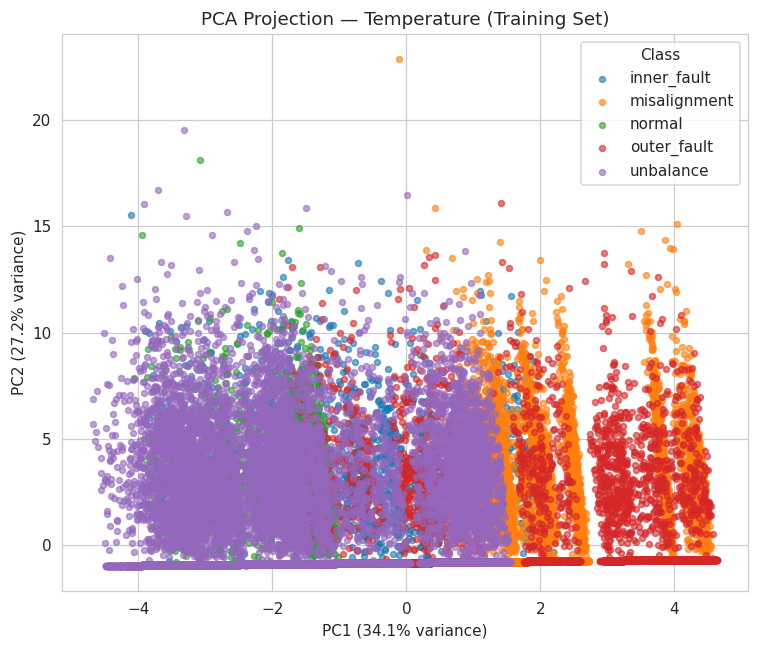

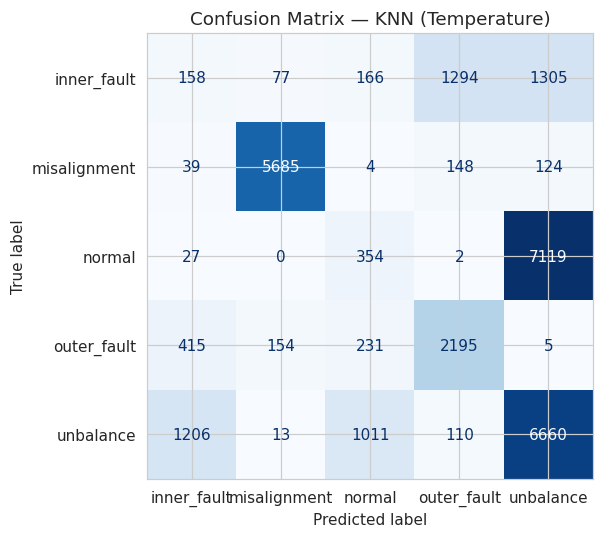

In [23]:
# ============================================================
# SECTION 12c: TEMPERATURE — VISUALIZATION
# ============================================================

plot_pca_projection(X_temp_train, y_temp_train, 'Temperature', save_path=f'{out}/temperature_pca_new.png')
plot_confusion_matrix(temperature_classifier, save_path=f'{out}/temperature_confusion_matrix_new.png')


In [24]:
# ============================================================
# SECTION 13a: COMPARATIVE SUMMARY
# ============================================================

comparison_table = pd.concat([current_classifier.summary(), temperature_classifier.summary()], ignore_index=True)
print("Comparative Summary — Current vs Temperature (Separate Models)")
print(comparison_table.to_string(index=False))
comparison_table.to_csv(f'{out}/knn_current_temperature_separate_summary.csv', index=False)


Comparative Summary — Current vs Temperature (Separate Models)
     Sensor  Best K  Weights    Metric  CV F1 (grouped)  Test Accuracy  Precision  Recall  F1-Score
    Current       7 distance manhattan           0.6759         0.5247     0.4535  0.5247    0.4796
Temperature      25  uniform euclidean           0.5379         0.5281     0.4635  0.5281    0.4698


In [25]:
# ============================================================
# SECTION 13b: MODEL PERSISTENCE
# ============================================================

joblib.dump(current_classifier.best_model, f'{out}/knn_current_model_new.joblib')
joblib.dump(current_classifier.scaler, f'{out}/current_scaler_new.joblib')
joblib.dump(temperature_classifier.best_model, f'{out}/knn_temperature_model_new.joblib')
joblib.dump(temperature_classifier.scaler, f'{out}/temperature_scaler_new.joblib')

print("Trained models and scalers saved to:", out)
print(os.listdir(out))


Trained models and scalers saved to: /content/drive/MyDrive/DATA/Output
['knn_comparison_summary.csv', 'knn_sensor_comparison.png', 'knn_vibration_model.joblib', 'vibration_scaler.joblib', 'knn_acoustic_model.joblib', 'acoustic_scaler.joblib', 'vibration_feature_distributions.png', 'vibration_pca_projection.png', 'vibration_confusion_matrix.png', 'vibration_k_sensitivity.png', 'current_feature_distributions.png', 'current_pca_projection.png', 'current_k_sensitivity.png', 'current_confusion_matrix.png', 'temperature_feature_distributions.png', 'temperature_pca_projection.png', 'temperature_k_sensitivity.png', 'temperature_confusion_matrix.png', 'knn_current_temperature_comparison.csv', 'knn_current_temperature_bar_comparison.png', 'knn_current_model.joblib', 'current_scaler.joblib', 'knn_temperature_model.joblib', 'temperature_scaler.joblib', 'vibration_multichannel_pca.png', 'vibration_feature_importance.png', 'vibration_confusion_matrix_multichannel.png', 'current_multichannel_pca.png